# Segmentación de árboles urbanos en nubes de puntos LiDAR con WHU-STree

Trabajo realizado por John Viana.

Este notebook tiene el código del proyecto de la electiva. El objetivo es entrenar una red neuronal que encuentre cada árbol de la calle dentro de una nube de puntos LiDAR, para poder hacer un inventario de arbolado urbano. Se usa el conjunto de datos WHU-STree, que tiene nubes de puntos de calles de las ciudades de Nanjing y Shenyang con cada árbol anotado.

El notebook sigue el mismo orden de la sección de materiales y métodos del documento. Primero se preparan el entorno y los datos, luego se hace el preprocesamiento, se arma y se entrena el modelo, después se separan los árboles con el agrupamiento por picos de densidad y al final se evalúa el modelo y se muestran los resultados.

Con este mismo notebook se corren todos los experimentos del documento. El experimento preliminar entrena y prueba con datos de Shenyang. El experimento E1 entrena y prueba en Nanjing, el E2 usa ese mismo modelo para probar en Shenyang, que es una ciudad que el modelo no vio, y el E3 entrena en Shenyang y prueba en Nanjing. Como E1 y E2 usan el mismo entrenamiento, se corren juntos.

### Cómo correrlo en Google Colab

Se abre este notebook en Colab, se escoge un entorno con GPU en el menú Entorno de ejecución y se ejecutan las celdas en orden. La primera vez, el notebook copia las nubes de puntos y las etiquetas desde el enlace de WHU-STree que entregan los autores a la carpeta WHU-STree de Mi unidad. Para esto Colab pide permiso para usar Google Drive de la cuenta. La copia se hace dentro de Drive, así que no se descarga nada al computador, y las siguientes veces el notebook lee los datos directamente de esa carpeta.

Si la sesión de Colab se desconecta, basta con volver a ejecutar todo desde el principio. El preprocesamiento y el entrenamiento se van guardando en Drive, entonces el notebook continúa donde había quedado.

## 1. Preparación del entorno

En esta celda se cargan las librerías. Si el notebook está corriendo en Colab, también se conecta Google Drive y se instala la librería plyfile, que sirve para leer los archivos de nubes de puntos. Luego se escoge el dispositivo, que en Colab debería ser la GPU.

In [1]:
import os
import sys
import json
import time
import random
import shutil
import subprocess

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "plyfile"], check=True)

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from plyfile import PlyData
from scipy import ndimage
from scipy.optimize import linear_sum_assignment
from scipy.spatial import cKDTree
from sklearn.cluster import DBSCAN

if torch.cuda.is_available():
    dispositivo = torch.device("cuda")
elif torch.backends.mps.is_available():
    dispositivo = torch.device("mps")
else:
    dispositivo = torch.device("cpu")
print("Dispositivo:", dispositivo, "| PyTorch:", torch.__version__)
if dispositivo.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Mounted at /content/drive
Dispositivo: cuda | PyTorch: 2.14.1+cu130
GPU: Tesla T4


### 1.1 Elección del experimento

Aquí se escoge qué experimento se va a correr. Primero se corre "E1_E2" y cuando termine se cambia a "E3" y se vuelve a ejecutar el notebook. El experimento "preliminar" es el que aparece en el documento con los datos de Shenyang.

Los demás valores son los de la metodología del documento, como el tamaño del vóxel, el tamaño de los bloques y la tasa de aprendizaje. El experimento preliminar usa 30 épocas de 100 iteraciones con lotes de 8 bloques, y los experimentos con Nanjing usan 60 épocas de 200 iteraciones con lotes de 16 bloques porque hay muchos más datos.

In [2]:
EXPERIMENTO = "E3"   # "preliminar", "E1_E2" o "E3"

def buscar_carpeta_datos():
    # busca en Drive la carpeta que tiene adentro whu-stree-nj y whu-stree-sy
    for base in ["/content/drive/MyDrive", "/content/drive/.shortcut-targets-by-id", "/content/drive/Shareddrives"]:
        if not os.path.isdir(base):
            continue
        for raiz, carpetas, _ in os.walk(base):
            if "whu-stree-nj" in carpetas and "whu-stree-sy" in carpetas \
                    and os.listdir(os.path.join(raiz, "whu-stree-nj")):
                return raiz
            if raiz.count(os.sep) - base.count(os.sep) >= 3:
                carpetas[:] = []   # no se baja más de tres niveles para que sea rápido
    return None


# carpeta compartida de WHU-STree que entregan los autores después de llenar el formulario
ID_CARPETA_WHU = "PEGAR_AQUI_EL_ID_DE_LA_CARPETA"

if EN_COLAB:
    MI_COPIA = "/content/drive/MyDrive/WHU-STree"
    if os.path.exists(os.path.join(MI_COPIA, "copia_completa.txt")):
        RUTA_DATOS, HAY_QUE_COPIAR = MI_COPIA, False
    else:
        RUTA_DATOS = buscar_carpeta_datos()
        HAY_QUE_COPIAR = RUTA_DATOS is None or RUTA_DATOS == MI_COPIA
    if HAY_QUE_COPIAR:
        print("Los datos se van a copiar a Mi unidad/WHU-STree en la siguiente sección.")
    else:
        print("Datos encontrados en Drive:", RUTA_DATOS)
    CARPETA_PROCESADOS = "/content/procesados"
    COPIA_EN_DRIVE = "/content/drive/MyDrive/arbolado_resultados/procesados"
    CARPETA_RESULTADOS = "/content/drive/MyDrive/arbolado_resultados/" + EXPERIMENTO
else:
    RUTA_DATOS = "data/WHU-STree"
    HAY_QUE_COPIAR = False
    CARPETA_PROCESADOS = "procesados"
    COPIA_EN_DRIVE = None
    CARPETA_RESULTADOS = "resultados/" + EXPERIMENTO
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)

NJ = "whu-stree-nj"
SY = "whu-stree-sy"
if EXPERIMENTO == "preliminar":
    CIUDAD_ENTRENAMIENTO = SY
    PRUEBAS = {"Preliminar": SY}
    EPOCAS, ITERACIONES, LOTE = 30, 100, 8
elif EXPERIMENTO == "E1_E2":
    CIUDAD_ENTRENAMIENTO = NJ
    PRUEBAS = {"E1": NJ, "E2": SY}
    EPOCAS, ITERACIONES, LOTE = 60, 200, 16
elif EXPERIMENTO == "E3":
    CIUDAD_ENTRENAMIENTO = SY
    PRUEBAS = {"E3": NJ}
    EPOCAS, ITERACIONES, LOTE = 60, 200, 16

TAM_VOXEL = 0.20          # metros
TAM_BLOQUE = 16.0         # metros
PASO_INFERENCIA = 8.0     # metros, los bloques se solapan a la mitad
PUNTOS_BLOQUE = 8192
TASA_APRENDIZAJE = 0.002
DECAIMIENTO_PESOS = 0.0001
LAMBDA_DESP = 1.0
VALIDAR_CADA = 5
SEMILLA = 0
TRABAJADORES = 2 if EN_COLAB else 0

print("Experimento:", EXPERIMENTO, "| entrena en:", CIUDAD_ENTRENAMIENTO, "| prueba en:", PRUEBAS)
print("Resultados en:", CARPETA_RESULTADOS)

Datos encontrados en Drive: /content/drive/MyDrive/WHU-STree
Experimento: E3 | entrena en: whu-stree-sy | prueba en: {'E3': 'whu-stree-nj'}
Resultados en: /content/drive/MyDrive/arbolado_resultados/E3


## 2. Datos

Cada ciudad tiene una carpeta por vía. Dentro de cada vía, la carpeta PCD tiene las nubes de puntos de cada recorrido en archivos .ply. Las etiquetas no vienen igual en todos los archivos. En los recorridos de entrenamiento de Nanjing, el mismo archivo .ply trae el campo tree, que dice a qué árbol pertenece cada punto, o el valor 0 si el punto no es árbol. En los recorridos de prueba de Nanjing y en todos los de Shenyang, el archivo .ply solo trae las coordenadas, y las etiquetas vienen aparte en la carpeta reference_data, con el valor -1 para los puntos que no son árbol. Las imágenes panorámicas no se usan en este trabajo.

Para dividir los datos se hace lo mismo que en el documento. En Nanjing se usa la partición oficial de prueba del archivo test_split.txt, que tiene 26 recorridos, y del resto se separa el 10 % de las vías para validación. En Shenyang no hay partición oficial, entonces en el experimento preliminar se deja la vía 05 para prueba y una de las otras vías para validación. Las divisiones se hacen por vías completas para que puntos de una misma calle no queden en conjuntos diferentes.

### 2.1 Copia de los datos a Mi unidad

Los autores comparten los datos en una carpeta de Google Drive. Si muchas personas descargan los mismos archivos, Drive bloquea las descargas por un tiempo, y eso pasó al intentar leerlos directamente del enlace. Por eso, la primera vez se copian a la carpeta WHU-STree de Mi unidad, porque una copia propia no tiene ese límite.

Primero se hace una lista de los archivos de la carpeta compartida sin entrar a las imágenes, que no se usan, y luego cada archivo se copia con la API de Google Drive. La copia se hace dentro de Drive, así que no gasta la conexión de Colab. Si algún archivo falla, basta con volver a ejecutar el notebook más tarde y solo se copian los que faltan. Cuando termina se guarda un archivo llamado copia_completa.txt para no repetir este paso.

In [3]:
ARCHIVOS_DRIVE = {}   # ruta dentro de la carpeta compartida -> identificador del archivo


def contenido_carpeta_drive(id_carpeta):
    # lista los archivos y carpetas de una carpeta compartida de Google Drive
    import requests
    from bs4 import BeautifulSoup
    respuesta = requests.get("https://drive.google.com/embeddedfolderview", params={"id": id_carpeta}, timeout=60)
    pagina = BeautifulSoup(respuesta.text, "html.parser")
    elementos = []
    for enlace in pagina.find_all("a"):
        href = enlace.get("href", "")
        nombre = enlace.get_text(strip=True)
        if "/file/d/" in href:
            elementos.append(("archivo", href.split("/file/d/")[1].split("/")[0], nombre))
        elif "/folders/" in href:
            elementos.append(("carpeta", href.split("/folders/")[1].split("?")[0], nombre))
    return elementos


def hacer_lista_de_archivos():
    # recorre la carpeta compartida sin entrar a las imágenes, que no se usan
    raiz = {n: i for t, i, n in contenido_carpeta_drive(ID_CARPETA_WHU) if t == "carpeta"}
    for ciudad in (NJ, SY):
        for tipo, ident, nombre in contenido_carpeta_drive(raiz[ciudad]):
            if tipo == "archivo":
                ARCHIVOS_DRIVE[f"{ciudad}/{nombre}"] = ident
            elif nombre == "reference_data":
                for _, i, n in contenido_carpeta_drive(ident):
                    ARCHIVOS_DRIVE[f"{ciudad}/reference_data/{n}"] = i
            else:
                for t, i, n in contenido_carpeta_drive(ident):
                    if t == "carpeta" and n == "PCD":
                        for _, i2, n2 in contenido_carpeta_drive(i):
                            ARCHIVOS_DRIVE[f"{ciudad}/{nombre}/PCD/{n2}"] = i2


if HAY_QUE_COPIAR:
    from google.colab import auth
    from googleapiclient.discovery import build
    auth.authenticate_user()   # Colab pide permiso para usar Google Drive
    servicio = build("drive", "v3")

    def carpeta_mia(nombre, padre):
        # busca una carpeta en Mi unidad y si no existe la crea
        consulta = (f"name = '{nombre}' and '{padre}' in parents and trashed = false "
                    "and mimeType = 'application/vnd.google-apps.folder'")
        encontradas = servicio.files().list(q=consulta, fields="files(id)").execute()["files"]
        if encontradas:
            return encontradas[0]["id"]
        cuerpo = {"name": nombre, "parents": [padre], "mimeType": "application/vnd.google-apps.folder"}
        return servicio.files().create(body=cuerpo, fields="id").execute()["id"]

    def nombres_en_carpeta(id_carpeta):
        nombres, pagina = set(), None
        while True:
            respuesta = servicio.files().list(q=f"'{id_carpeta}' in parents and trashed = false",
                                              fields="nextPageToken, files(name)", pageSize=1000,
                                              pageToken=pagina).execute()
            nombres |= {f["name"] for f in respuesta["files"]}
            pagina = respuesta.get("nextPageToken")
            if not pagina:
                return nombres

    hacer_lista_de_archivos()
    print("Archivos para copiar:", len(ARCHIVOS_DRIVE))
    ids_carpetas = {"": carpeta_mia("WHU-STree", "root")}
    ya_estan = {}
    fallidos = []
    inicio = time.time()
    for k, ruta in enumerate(sorted(ARCHIVOS_DRIVE), 1):
        *carpetas, nombre = ruta.split("/")
        camino = ""
        for c in carpetas:
            padre = ids_carpetas[camino]
            camino = camino + "/" + c
            if camino not in ids_carpetas:
                ids_carpetas[camino] = carpeta_mia(c, padre)
        destino = ids_carpetas[camino]
        if destino not in ya_estan:
            ya_estan[destino] = nombres_en_carpeta(destino)
        if nombre in ya_estan[destino]:
            continue   # ya se había copiado antes
        try:
            servicio.files().copy(fileId=ARCHIVOS_DRIVE[ruta], body={"name": nombre, "parents": [destino]},
                                  fields="id").execute()
            print(f"{k}/{len(ARCHIVOS_DRIVE)} copiado {ruta} ({time.time() - inicio:.0f} s)")
        except Exception as error:
            fallidos.append(ruta)
            print("No se pudo copiar", ruta, error)
    if fallidos:
        raise RuntimeError(f"Faltan {len(fallidos)} archivos por copiar. Hay que volver a ejecutar el notebook "
                           "más tarde y solo se copiarán los que faltan.")

    # se vuelve a conectar Drive para que Colab vea los archivos nuevos
    drive.mount("/content/drive", force_remount=True)
    RUTA_DATOS = MI_COPIA
    for espera in range(10):
        n_ply = sum(f.endswith(".ply") for _, _, archivos in os.walk(RUTA_DATOS) for f in archivos)
        if n_ply >= sum(r.endswith(".ply") for r in ARCHIVOS_DRIVE):
            break
        time.sleep(30)
    with open(os.path.join(RUTA_DATOS, "copia_completa.txt"), "w") as f:
        f.write("copia terminada\n")
    HAY_QUE_COPIAR = False
    print("Copia completa en Mi unidad/WHU-STree, desde ahora los datos se leen de ahí.")


In [4]:
def listar_escenas(ciudad):
    # devuelve una lista con (vía, recorrido, ruta del archivo .ply)
    carpeta = os.path.join(RUTA_DATOS, ciudad)
    escenas = []
    for via in sorted(os.listdir(carpeta)):
        carpeta_pcd = os.path.join(carpeta, via, "PCD")
        if not os.path.isdir(carpeta_pcd):
            continue
        for archivo in sorted(os.listdir(carpeta_pcd)):
            if archivo.endswith(".ply"):
                escenas.append((via, archivo[:-4], os.path.join(carpeta_pcd, archivo)))
    return escenas


def leer_particion_oficial():
    # el archivo tiene líneas como "08,1-2", que es la vía 08 y el recorrido 1-2
    prueba = set()
    with open(os.path.join(RUTA_DATOS, NJ, "test_split.txt")) as f:
        for linea in f:
            partes = [p.strip() for p in linea.split(",")]
            if len(partes) == 2 and not partes[0].startswith("road"):
                prueba.add((partes[0], partes[1]))
    return prueba


def separar_validacion(escenas, fraccion):
    # se escogen vías completas al azar para validación
    vias = sorted({e[0] for e in escenas})
    random.Random(SEMILLA).shuffle(vias)
    n_val = max(1, round(len(vias) * fraccion)) if len(vias) > 1 else 0
    vias_val = set(vias[:n_val])
    entrenamiento = [e for e in escenas if e[0] not in vias_val]
    validacion = [e for e in escenas if e[0] in vias_val]
    return entrenamiento, validacion


def dividir_ciudad(ciudad):
    escenas = listar_escenas(ciudad)
    if ciudad == NJ:
        oficial = leer_particion_oficial()
        prueba = [e for e in escenas if (e[0], e[1]) in oficial]
        resto = [e for e in escenas if (e[0], e[1]) not in oficial]
        entrenamiento, validacion = separar_validacion(resto, 0.1)
    elif EXPERIMENTO == "preliminar":
        prueba = [e for e in escenas if e[0] == "05"]
        resto = [e for e in escenas if e[0] != "05"]
        entrenamiento, validacion = separar_validacion(resto, 0.2)
    elif ciudad == CIUDAD_ENTRENAMIENTO:
        # Shenyang en E3, todas sus vías sirven para entrenar y validar
        prueba = []
        entrenamiento, validacion = separar_validacion(escenas, 0.2)
    else:
        # Shenyang en E2, es la ciudad no vista y todas sus vías son de prueba
        prueba, entrenamiento, validacion = escenas, [], []
    return {"entrenamiento": entrenamiento, "validacion": validacion, "prueba": prueba}


PARTICIONES = {}
for ciudad in [CIUDAD_ENTRENAMIENTO] + list(PRUEBAS.values()):
    if ciudad not in PARTICIONES:
        PARTICIONES[ciudad] = dividir_ciudad(ciudad)
        for nombre, lista in PARTICIONES[ciudad].items():
            print(f"{ciudad} {nombre}: {len(lista)} recorridos, vías {sorted({e[0] for e in lista})}")

whu-stree-sy entrenamiento: 7 recorridos, vías ['00', '01', '02', '03', '05']
whu-stree-sy validacion: 1 recorridos, vías ['04']
whu-stree-sy prueba: 0 recorridos, vías []
whu-stree-nj entrenamiento: 78 recorridos, vías ['01', '02', '03', '04', '05', '06', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '26', '27', '29', '30', '31', '32', '33', '34']
whu-stree-nj validacion: 6 recorridos, vías ['00', '07', '28']
whu-stree-nj prueba: 26 recorridos, vías ['02', '03', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '20', '21', '25', '28', '29', '31', '33', '34']


## 3. Preprocesamiento

El preprocesamiento tiene tres pasos, igual que en el documento. Primero se calcula el centro 3D de cada árbol con la nube completa, porque la red va a aprender a mover cada punto hacia el centro de su árbol. Luego se reduce la nube con vóxeles de 0,20 m, dejando un punto al azar por cada cubo de 20 cm de lado, para que la nube sea más liviana y la cantidad de puntos se parezca entre ciudades. Por último, como los datos no traen la intensidad del láser, se calcula la altura de cada punto sobre el suelo tomando como referencia el punto más bajo de su celda de 2 por 2 m vista desde arriba.

Cada recorrido procesado se guarda en una carpeta con varios archivos .npy. Después se abren con la opción mmap_mode de numpy, que lee del disco solo los puntos que se necesitan, y así no hace falta cargar todo Nanjing en la memoria RAM. En Colab los archivos se guardan en el disco de la máquina, que es más rápido, y también se copian a Drive para no repetir este paso si la sesión se cae.

In [5]:
def leer_nube(ciudad, via, recorrido, ruta_ply):
    datos = PlyData.read(ruta_ply)["vertex"].data
    xyz = np.stack([datos["x"], datos["y"], datos["z"]], axis=1).astype(np.float64)
    if "tree" in datos.dtype.names:
        # entrenamiento de Nanjing, la etiqueta del árbol viene en el mismo archivo
        instancia = datos["tree"].astype(np.int64)
    else:
        # prueba de Nanjing y Shenyang, las etiquetas vienen en reference_data
        ruta_etiquetas = os.path.join(RUTA_DATOS, ciudad, "reference_data", f"{via}_{recorrido}.npy")
        etiquetas = np.load(ruta_etiquetas)
        if etiquetas.ndim == 2:
            # en la prueba de Nanjing vienen dos columnas, el árbol y la especie
            etiquetas = etiquetas[:, 0]
        instancia = etiquetas.astype(np.int64)
    assert len(instancia) == len(xyz), "las etiquetas no coinciden con la nube"
    instancia[instancia < 0] = 0   # 0 significa que el punto no es árbol
    return xyz, instancia

def centros_de_arboles(xyz, instancia):
    # cada punto de árbol recibe el centro (promedio de sus puntos) del árbol al que pertenece
    centros = np.zeros_like(xyz)
    es_arbol = instancia > 0
    ids, inv = np.unique(instancia[es_arbol], return_inverse=True)
    cuenta = np.bincount(inv)
    for j in range(3):
        promedio = np.bincount(inv, weights=xyz[es_arbol, j]) / cuenta
        centros[es_arbol, j] = promedio[inv]
    return centros


def numero_de_celda(xyz, tam):
    # convierte la posición de cada punto en un solo número que identifica su celda
    k = np.floor((xyz - xyz.min(0)) / tam).astype(np.int64)
    dims = k.max(0) + 1
    if xyz.shape[1] == 3:
        return (k[:, 0] * dims[1] + k[:, 1]) * dims[2] + k[:, 2]
    return k[:, 0] * dims[1] + k[:, 1]


def reducir_con_voxeles(xyz, tam):
    rng = np.random.default_rng(0)
    orden = rng.permutation(len(xyz))
    _, primero = np.unique(numero_de_celda(xyz[orden], tam), return_index=True)
    return np.sort(orden[primero])


def altura_sobre_suelo(xyz, tam_celda=2.0):
    celda = numero_de_celda(xyz[:, :2], tam_celda)
    _, inv = np.unique(celda, return_inverse=True)
    z_minimo = np.full(inv.max() + 1, np.inf)
    np.minimum.at(z_minimo, inv, xyz[:, 2])
    return (xyz[:, 2] - z_minimo[inv]).astype(np.float32)


def preprocesar_recorrido(ciudad, via, recorrido, ruta_ply):
    carpeta = os.path.join(CARPETA_PROCESADOS, ciudad, f"{via}_{recorrido}")
    if os.path.exists(os.path.join(carpeta, "info.json")):
        return carpeta   # ya estaba procesado
    xyz, instancia = leer_nube(ciudad, via, recorrido, ruta_ply)
    centros = centros_de_arboles(xyz, instancia)
    idx = reducir_con_voxeles(xyz, TAM_VOXEL)
    puntos = xyz[idx]
    origen = puntos.min(axis=0)
    os.makedirs(carpeta, exist_ok=True)
    np.save(os.path.join(carpeta, "xyz.npy"), (puntos - origen).astype(np.float32))
    np.save(os.path.join(carpeta, "altura.npy"), altura_sobre_suelo(puntos))
    np.save(os.path.join(carpeta, "instancia.npy"), instancia[idx].astype(np.int32))
    centro_rel = np.where(instancia[idx, None] > 0, centros[idx] - origen, 0)
    np.save(os.path.join(carpeta, "centro.npy"), centro_rel.astype(np.float32))
    info = {"puntos_originales": int(len(xyz)), "puntos": int(len(idx)),
            "arboles": int(len(np.unique(instancia[instancia > 0])))}
    with open(os.path.join(carpeta, "info.json"), "w") as f:
        json.dump(info, f)
    return carpeta


# recorridos que necesita este experimento
necesarios = [(CIUDAD_ENTRENAMIENTO, e) for e in PARTICIONES[CIUDAD_ENTRENAMIENTO]["entrenamiento"]]
necesarios += [(CIUDAD_ENTRENAMIENTO, e) for e in PARTICIONES[CIUDAD_ENTRENAMIENTO]["validacion"]]
for ciudad in PRUEBAS.values():
    necesarios += [(ciudad, e) for e in PARTICIONES[ciudad]["prueba"]]

inicio = time.time()
for i, (ciudad, (via, recorrido, ruta_ply)) in enumerate(necesarios, 1):
    nombre = f"{via}_{recorrido}"
    carpeta_local = os.path.join(CARPETA_PROCESADOS, ciudad, nombre)
    carpeta_drive = os.path.join(COPIA_EN_DRIVE, ciudad, nombre) if COPIA_EN_DRIVE else None
    if carpeta_drive and os.path.exists(os.path.join(carpeta_drive, "info.json")) \
            and not os.path.exists(os.path.join(carpeta_local, "info.json")):
        shutil.copytree(carpeta_drive, carpeta_local, dirs_exist_ok=True)   # se recupera de Drive
    preprocesar_recorrido(ciudad, via, recorrido, ruta_ply)
    if carpeta_drive and not os.path.exists(os.path.join(carpeta_drive, "info.json")):
        shutil.copytree(carpeta_local, carpeta_drive, dirs_exist_ok=True)   # copia de respaldo
    print(f"{i}/{len(necesarios)} {ciudad} {nombre} listo ({time.time() - inicio:.0f} s)")

1/34 whu-stree-sy 00_1 listo (6 s)
2/34 whu-stree-sy 01_1 listo (10 s)
3/34 whu-stree-sy 01_2 listo (17 s)
4/34 whu-stree-sy 01_3 listo (23 s)
5/34 whu-stree-sy 02_1 listo (30 s)
6/34 whu-stree-sy 03_1 listo (38 s)
7/34 whu-stree-sy 05_1 listo (43 s)
8/34 whu-stree-sy 04_1 listo (50 s)
9/34 whu-stree-nj 02_1 listo (53 s)
10/34 whu-stree-nj 03_3 listo (57 s)
11/34 whu-stree-nj 07_2 listo (60 s)
12/34 whu-stree-nj 08_1-1 listo (63 s)
13/34 whu-stree-nj 08_1-2 listo (65 s)
14/34 whu-stree-nj 09_1 listo (69 s)
15/34 whu-stree-nj 09_3 listo (73 s)
16/34 whu-stree-nj 10_2 listo (77 s)
17/34 whu-stree-nj 11_3-2 listo (81 s)
18/34 whu-stree-nj 12_2-1 listo (86 s)
19/34 whu-stree-nj 13_1-1 listo (91 s)
20/34 whu-stree-nj 14_2 listo (97 s)
21/34 whu-stree-nj 15_1 listo (100 s)
22/34 whu-stree-nj 15_2-1 listo (103 s)
23/34 whu-stree-nj 16_3-3 listo (106 s)
24/34 whu-stree-nj 17_2 listo (110 s)
25/34 whu-stree-nj 18_2-2 listo (114 s)
26/34 whu-stree-nj 20_4 listo (117 s)
27/34 whu-stree-nj 21_2 li

In [6]:
for ciudad, particion in PARTICIONES.items():
    for nombre, lista in particion.items():
        if not lista:
            continue
        infos = []
        for via, recorrido, _ in lista:
            ruta = os.path.join(CARPETA_PROCESADOS, ciudad, f"{via}_{recorrido}", "info.json")
            if os.path.exists(ruta):
                infos.append(json.load(open(ruta)))
        if infos:
            originales = sum(x["puntos_originales"] for x in infos)
            puntos = sum(x["puntos"] for x in infos)
            arboles = sum(x["arboles"] for x in infos)
            print(f"{ciudad} {nombre}: {len(infos)} recorridos, {arboles} árboles, "
                  f"{originales / 1e6:.1f} M de puntos que quedan en {puntos / 1e6:.1f} M ({100 * puntos / originales:.1f} %)")

whu-stree-sy entrenamiento: 7 recorridos, 2384 árboles, 243.2 M de puntos que quedan en 31.0 M (12.8 %)
whu-stree-sy validacion: 1 recorridos, 280 árboles, 51.2 M de puntos que quedan en 6.1 M (11.9 %)
whu-stree-nj prueba: 26 recorridos, 3586 árboles, 508.2 M de puntos que quedan en 58.7 M (11.5 %)


## 4. Bloques para entrenar y para predecir

Una calle completa tiene millones de puntos y no cabe de una vez en la red, entonces se trabaja con bloques de 16 por 16 m vistos desde arriba. Para entrenar, cada bloque se centra en un punto al azar, que la mitad de las veces es un punto de árbol para que las dos clases estén equilibradas, y se toman 8192 puntos al azar dentro del bloque.

Las coordenadas de cada bloque se normalizan respecto a su centro y a su punto más bajo, y cada punto entra a la red con cuatro valores, que son x, y, z y la altura sobre el suelo dividida entre 10. Durante el entrenamiento también se hace aumento de datos con rotaciones al azar alrededor del eje vertical, cambios de escala entre 0,9 y 1,1, reflejos en el eje x y un ruido de 1 cm en las coordenadas. El desplazamiento hacia el centro del árbol se rota y se escala igual que los puntos.

Para predecir una calle completa se recorre con bloques que se solapan a la mitad, y cada bloque se parte en grupos de 8192 puntos para que todos los puntos reciban al menos una predicción.

In [7]:
class Escena:
    # abre los archivos de un recorrido procesado sin cargarlos completos en memoria
    def __init__(self, carpeta):
        self.nombre = os.path.basename(carpeta)
        self.xyz = np.load(os.path.join(carpeta, "xyz.npy"), mmap_mode="r")
        self.altura = np.load(os.path.join(carpeta, "altura.npy"), mmap_mode="r")
        self.instancia = np.load(os.path.join(carpeta, "instancia.npy"), mmap_mode="r")
        self.centro = np.load(os.path.join(carpeta, "centro.npy"), mmap_mode="r")

    def __len__(self):
        return len(self.xyz)


def cargar_escenas(ciudad, particion):
    return [Escena(os.path.join(CARPETA_PROCESADOS, ciudad, f"{via}_{recorrido}"))
            for via, recorrido, _ in PARTICIONES[ciudad][particion]]


def preparar_bloque(escena, idx, rng, aumentar=False):
    if len(idx) >= PUNTOS_BLOQUE:
        sel = rng.choice(idx, PUNTOS_BLOQUE, replace=False)
    else:
        sel = np.concatenate([idx, rng.choice(idx, PUNTOS_BLOQUE - len(idx), replace=True)])
    p = np.asarray(escena.xyz[sel], dtype=np.float32)
    centro = np.asarray(escena.centro[sel], dtype=np.float32)
    inst = np.asarray(escena.instancia[sel], dtype=np.int64)
    desp = np.where(inst[:, None] > 0, centro - p, 0).astype(np.float32)

    # se normaliza respecto al centro del bloque y a su punto más bajo
    ref = np.array([p[:, 0].mean(), p[:, 1].mean(), p[:, 2].min()], dtype=np.float32)
    p = p - ref

    if aumentar:
        angulo = rng.uniform(0, 2 * np.pi)
        c, s = np.cos(angulo), np.sin(angulo)
        rotacion = np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]], dtype=np.float32)
        escala = rng.uniform(0.9, 1.1)
        p = (p @ rotacion.T) * escala
        desp = (desp @ rotacion.T) * escala
        if rng.random() < 0.5:
            p[:, 0] *= -1
            desp[:, 0] *= -1
        p = p + rng.normal(0, 0.01, p.shape).astype(np.float32)

    entrada = np.concatenate([p, np.asarray(escena.altura[sel], np.float32)[:, None] / 10.0], axis=1)
    return {"xyz": torch.from_numpy(p.astype(np.float32)),
            "entrada": torch.from_numpy(entrada.astype(np.float32)),
            "es_arbol": torch.from_numpy((inst > 0).astype(np.int64)),
            "desp": torch.from_numpy(desp),
            "sel": torch.from_numpy(sel.astype(np.int64))}


class BloquesAleatorios(torch.utils.data.Dataset):
    def __init__(self, escenas, n_bloques):
        self.escenas = escenas
        self.n_bloques = n_bloques
        tamanos = np.array([len(e) for e in escenas], dtype=np.float64)
        self.prob = tamanos / tamanos.sum()   # las calles grandes salen más veces
        self.epoca = 0

    def __len__(self):
        return self.n_bloques

    def __getitem__(self, i):
        rng = np.random.default_rng((SEMILLA, self.epoca, i))
        escena = self.escenas[rng.choice(len(self.escenas), p=self.prob)]
        if rng.random() < 0.5:
            arboles = np.flatnonzero(np.asarray(escena.instancia) > 0)
            centro = escena.xyz[rng.choice(arboles)] if len(arboles) else escena.xyz[rng.integers(len(escena))]
        else:
            centro = escena.xyz[rng.integers(len(escena))]
        xy = np.asarray(escena.xyz[:, :2])
        dentro = (np.abs(xy[:, 0] - centro[0]) <= TAM_BLOQUE / 2) & (np.abs(xy[:, 1] - centro[1]) <= TAM_BLOQUE / 2)
        return preparar_bloque(escena, np.flatnonzero(dentro), rng, aumentar=True)


def bloques_de_toda_la_escena(escena):
    rng = np.random.default_rng(0)
    xy = np.asarray(escena.xyz[:, :2])
    minimo, maximo = xy.min(0), xy.max(0)
    xs = np.arange(minimo[0], max(maximo[0] - TAM_BLOQUE, minimo[0]) + PASO_INFERENCIA, PASO_INFERENCIA)
    ys = np.arange(minimo[1], max(maximo[1] - TAM_BLOQUE, minimo[1]) + PASO_INFERENCIA, PASO_INFERENCIA)
    for x0 in xs:
        franja = np.flatnonzero((xy[:, 0] >= x0) & (xy[:, 0] <= x0 + TAM_BLOQUE))
        if len(franja) == 0:
            continue
        y_franja = xy[franja, 1]
        for y0 in ys:
            idx = franja[(y_franja >= y0) & (y_franja <= y0 + TAM_BLOQUE)]
            if len(idx) < 32:
                continue
            idx = rng.permutation(idx)
            for k in range(0, len(idx), PUNTOS_BLOQUE):
                grupo = idx[k:k + PUNTOS_BLOQUE]
                if len(grupo) < PUNTOS_BLOQUE // 4 and k > 0:
                    grupo = np.concatenate([grupo, idx[:PUNTOS_BLOQUE - len(grupo)]])
                yield preparar_bloque(escena, grupo, rng)

## 5. Modelo

La red sigue la idea de PointNet++. El codificador tiene cuatro niveles y en cada uno se queda con la cuarta parte de los puntos, escogidos al azar como en RandLA-Net, así que pasa de 8192 a 2048, 512, 128 y 32 puntos. Para cada punto que queda se buscan sus 16 vecinos más cercanos, se juntan sus posiciones relativas con sus características y se pasan por una red pequeña de tres capas, y al final se toma el valor máximo entre los vecinos. Los cuatro niveles producen 64, 128, 256 y 512 canales.

El decodificador hace el camino de vuelta hasta los 8192 puntos. En cada nivel pasa las características a los puntos del nivel anterior con un promedio ponderado de los tres vecinos más cercanos y las junta con las del codificador, que es lo que se conoce como conexiones de salto.

Al final hay dos cabezas. La cabeza semántica dice si cada punto es árbol o no, y la cabeza de desplazamiento predice el vector que lleva cada punto hasta el centro de su árbol. La red está escrita solo con operaciones normales de PyTorch, por eso corre igual en la GPU de Colab que en un computador Apple.

In [8]:
def tomar_puntos(x, idx):
    # x tiene forma (lote, puntos, canales) e idx dice qué puntos tomar de cada ejemplo
    lote = x.shape[0]
    forma = idx.shape
    plano = idx.reshape(lote, -1)
    out = torch.gather(x, 1, plano.unsqueeze(-1).expand(-1, -1, x.shape[-1]))
    return out.reshape(*forma, x.shape[-1])


def vecinos_cercanos(consulta, base, k):
    distancias = torch.cdist(consulta, base)
    return distancias.topk(k, dim=-1, largest=False)


def capas(canales, dims=1):
    # capas convolucionales 1x1 con normalización por lotes y ReLU
    conv = nn.Conv1d if dims == 1 else nn.Conv2d
    bn = nn.BatchNorm1d if dims == 1 else nn.BatchNorm2d
    lista = []
    for a, b in zip(canales[:-1], canales[1:]):
        lista += [conv(a, b, 1, bias=False), bn(b), nn.ReLU(inplace=True)]
    return nn.Sequential(*lista)


class Abstraccion(nn.Module):
    # un nivel del codificador: muestreo al azar, vecinos cercanos, red pequeña y máximo
    def __init__(self, n_salida, k, c_entrada, canales):
        super().__init__()
        self.n_salida = n_salida
        self.k = k
        self.mlp = capas([c_entrada + 3] + canales, dims=2)

    def forward(self, xyz, caract):
        lote, n, _ = xyz.shape
        elegidos = torch.stack([torch.randperm(n, device=xyz.device)[: self.n_salida] for _ in range(lote)])
        nuevos = tomar_puntos(xyz, elegidos)
        _, vecinos = vecinos_cercanos(nuevos, xyz, self.k)
        relativos = tomar_puntos(xyz, vecinos) - nuevos.unsqueeze(2)
        escala = relativos.norm(dim=-1).amax(dim=(1, 2), keepdim=True).unsqueeze(-1).clamp_min(1e-6)
        grupo = torch.cat([relativos / escala, tomar_puntos(caract, vecinos)], dim=-1)
        salida = self.mlp(grupo.permute(0, 3, 1, 2)).amax(dim=-1)
        return nuevos, salida.transpose(1, 2)


class Propagacion(nn.Module):
    # un nivel del decodificador: interpolación con 3 vecinos y conexión de salto
    def __init__(self, c_entrada, canales):
        super().__init__()
        self.mlp = capas([c_entrada] + canales, dims=1)

    def forward(self, xyz_fino, xyz_grueso, caract_fino, caract_grueso):
        dist, idx = vecinos_cercanos(xyz_fino, xyz_grueso, 3)
        pesos = 1.0 / dist.clamp_min(1e-8)
        pesos = pesos / pesos.sum(-1, keepdim=True)
        interpolado = (tomar_puntos(caract_grueso, idx) * pesos.unsqueeze(-1)).sum(2)
        juntas = torch.cat([interpolado, caract_fino], dim=-1)
        return self.mlp(juntas.transpose(1, 2)).transpose(1, 2)


class SegmentadorArboles(nn.Module):
    def __init__(self, canales=(64, 128, 256, 512), k=16):
        super().__init__()
        self.entrada = capas([4, 32])
        niveles, c_ant, n = [], 32, PUNTOS_BLOQUE
        for c in canales:
            n = n // 4
            niveles.append(Abstraccion(n, k, c_ant, [c // 2, c // 2, c]))
            c_ant = c
        self.niveles = nn.ModuleList(niveles)
        dims = [32] + list(canales)
        props = []
        for i in range(len(canales), 0, -1):
            c_sal = max(dims[i - 1], 64)
            props.append(Propagacion(c_ant + dims[i - 1], [c_sal, c_sal]))
            c_ant = c_sal
        self.props = nn.ModuleList(props)
        self.cabeza_sem = nn.Sequential(capas([c_ant, 64]), nn.Dropout(0.3), nn.Conv1d(64, 2, 1))
        self.cabeza_desp = nn.Sequential(capas([c_ant, 64]), nn.Conv1d(64, 3, 1))

    def forward(self, xyz, entrada):
        caract = self.entrada(entrada.transpose(1, 2)).transpose(1, 2)
        pila = [(xyz, caract)]
        x, f = xyz, caract
        for nivel in self.niveles:
            x, f = nivel(x, f)
            pila.append((x, f))
        for prop, (x_fino, f_fino) in zip(self.props, reversed(pila[:-1])):
            f = prop(x_fino, x, f_fino, f)
            x = x_fino
        f = f.transpose(1, 2)
        return self.cabeza_sem(f).transpose(1, 2), self.cabeza_desp(f).transpose(1, 2)


modelo = SegmentadorArboles().to(dispositivo)
print("Parámetros entrenables:", sum(p.numel() for p in modelo.parameters()))

Parámetros entrenables: 718757


## 6. Agrupamiento y métricas

Después de la red, los puntos que son árbol se mueven según el desplazamiento predicho y se miran desde arriba. Si la red funciona bien, los puntos de cada árbol quedan amontonados cerca de su centro. Con esos puntos se hace un mapa de densidad en una cuadrícula de 0,2 m, se suaviza con un filtro gaussiano y los puntos de máxima densidad se toman como centros de los árboles. Cada punto se asigna al centro más cercano y se eliminan los árboles con muy pocos puntos.

Primero se probó DBSCAN, que es el método que se usa normalmente, pero DBSCAN une árboles vecinos cuando los desplazamientos no son exactos. Por eso se cambió a los picos de densidad, como se explica en el documento. La función de DBSCAN se deja solo para comparar.

Para medir los resultados se usan las métricas de WHU-STree. Cada árbol predicho se empareja con un árbol real, y el emparejamiento cuenta como correcto si la intersección sobre la unión (IoU) entre los dos es de al menos 0,5. Con eso se calculan la tasa de detección (Det), la tasa de omisión (Omi), la tasa de comisión (Com) y el F1. También se calculan el mIoU de la clasificación árbol o no árbol y la calidad panóptica (PQ).

In [9]:
def agrupar_picos(xyz, desp, es_arbol, sigma=0.8, dist_min=2.0, min_puntos=100, celda=0.2):
    pred = np.zeros(len(xyz), dtype=np.int64)
    idx = np.flatnonzero(es_arbol)
    if len(idx) == 0:
        return pred
    movidos = xyz[idx, :2] + desp[idx, :2]
    origen = movidos.min(0)
    k = np.floor((movidos - origen) / celda).astype(np.int64)
    densidad = np.zeros(k.max(0) + 1)
    np.add.at(densidad, (k[:, 0], k[:, 1]), 1)
    densidad = ndimage.gaussian_filter(densidad, sigma / celda)
    r = max(1, int(round(dist_min / celda / 2)))
    maximos = ndimage.maximum_filter(densidad, size=2 * r + 1)
    umbral = 0.3 * min_puntos / (2 * np.pi * (sigma / celda) ** 2)
    picos = np.argwhere((densidad == maximos) & (densidad > umbral))
    if len(picos) == 0:
        return pred
    centros = origen + (picos + 0.5) * celda
    _, cercano = cKDTree(centros).query(movidos)
    cuenta = np.bincount(cercano, minlength=len(centros))
    valido = cuenta >= min_puntos
    nuevo_id = np.where(valido, np.cumsum(valido), 0)
    pred[idx] = nuevo_id[cercano]
    return pred


def agrupar_dbscan(xyz, desp, es_arbol, eps=0.6, min_muestras=10, min_puntos=50, celda=0.1):
    # solo para comparar, los puntos se juntan en celdas de 10 cm para que DBSCAN sea rápido
    pred = np.zeros(len(xyz), dtype=np.int64)
    idx = np.flatnonzero(es_arbol)
    if len(idx) == 0:
        return pred
    movidos = xyz[idx, :2] + desp[idx, :2]
    celda_de_punto = numero_de_celda(movidos, celda)
    _, inv, peso = np.unique(celda_de_punto, return_inverse=True, return_counts=True)
    centros = np.stack([np.bincount(inv, weights=movidos[:, j]) / peso for j in range(2)], axis=1)
    etiquetas = DBSCAN(eps=eps, min_samples=min_muestras).fit_predict(centros, sample_weight=peso)[inv]
    validas = etiquetas >= 0
    if validas.any():
        _, inv2, tam = np.unique(etiquetas[validas], return_inverse=True, return_counts=True)
        nuevo_id = np.cumsum(tam >= min_puntos) * (tam >= min_puntos)
        pred[idx[validas]] = nuevo_id[inv2]
    return pred


def emparejar(pred, real):
    # empareja árboles predichos y reales uno a uno buscando la mayor IoU total
    ids_p = np.unique(pred[pred > 0])
    ids_r = np.unique(real[real > 0])
    if len(ids_p) == 0 or len(ids_r) == 0:
        return {"tp": 0, "fp": len(ids_p), "fn": len(ids_r), "suma_iou": 0.0}
    pos_p = {v: i for i, v in enumerate(ids_p)}
    pos_r = {v: i for i, v in enumerate(ids_r)}
    ambos = (pred > 0) & (real > 0)
    interseccion = np.zeros((len(ids_p), len(ids_r)))
    pares, cuentas = np.unique(np.stack([pred[ambos], real[ambos]], 1), axis=0, return_counts=True)
    for (a, b), c in zip(pares, cuentas):
        interseccion[pos_p[a], pos_r[b]] = c
    tam_p = np.unique(pred[pred > 0], return_counts=True)[1][:, None]
    tam_r = np.unique(real[real > 0], return_counts=True)[1][None, :]
    iou = interseccion / (tam_p + tam_r - interseccion)
    filas, columnas = linear_sum_assignment(-iou)
    correctos = iou[filas, columnas] >= 0.5
    tp = int(correctos.sum())
    return {"tp": tp, "fp": len(ids_p) - tp, "fn": len(ids_r) - tp,
            "suma_iou": float(iou[filas, columnas][correctos].sum())}


def metricas_de_arboles(conteo):
    tp, fp, fn = conteo["tp"], conteo["fp"], conteo["fn"]
    det = tp / max(tp + fn, 1)
    precision = tp / max(tp + fp, 1)
    f1 = 2 * precision * det / max(precision + det, 1e-9)
    sq = conteo["suma_iou"] / max(tp, 1)
    rq = tp / max(tp + 0.5 * fp + 0.5 * fn, 1e-9)
    return {"det": det, "omi": 1 - det, "com": fp / max(tp + fp, 1), "f1": f1, "pq": sq * rq,
            "arboles_reales": tp + fn, "arboles_predichos": tp + fp}


def miou(pred, real):
    ious = []
    for c in (0, 1):
        tp = np.sum((pred == c) & (real == c))
        fp = np.sum((pred == c) & (real != c))
        fn = np.sum((pred != c) & (real == c))
        ious.append(tp / max(tp + fp + fn, 1))
    return {"miou": float(np.mean(ious)), "iou_arbol": float(ious[1]), "oa": float(np.mean(pred == real))}


@torch.no_grad()
def predecir_escena(modelo, escena, lote=8):
    # se predice por bloques y se promedian las predicciones de los bloques que se solapan
    modelo.eval()
    n = len(escena)
    suma_prob = np.zeros((n, 2), np.float32)
    suma_desp = np.zeros((n, 3), np.float32)
    cuenta = np.zeros(n, np.float32)
    pendientes = []

    def correr(bloques):
        xyz = torch.stack([b["xyz"] for b in bloques]).to(dispositivo)
        entrada = torch.stack([b["entrada"] for b in bloques]).to(dispositivo)
        logits, desp = modelo(xyz, entrada)
        prob = torch.softmax(logits, -1).cpu().numpy()
        desp = desp.cpu().numpy()
        for j, b in enumerate(bloques):
            sel = b["sel"].numpy()
            np.add.at(suma_prob, sel, prob[j])
            np.add.at(suma_desp, sel, desp[j])
            np.add.at(cuenta, sel, 1)

    for bloque in bloques_de_toda_la_escena(escena):
        pendientes.append(bloque)
        if len(pendientes) == lote:
            correr(pendientes)
            pendientes = []
    if pendientes:
        correr(pendientes)
    c = np.maximum(cuenta, 1)[:, None]
    return {"es_arbol": (suma_prob[:, 1] / c[:, 0] >= 0.5), "desp": suma_desp / c}


def evaluar(escenas, predicciones, parametros, sin_desplazamiento=False):
    conteo = {"tp": 0, "fp": 0, "fn": 0, "suma_iou": 0.0}
    sem_pred, sem_real = [], []
    for escena, p in zip(escenas, predicciones):
        xyz = np.asarray(escena.xyz, np.float32)
        real = np.asarray(escena.instancia)
        desp = np.zeros_like(p["desp"]) if sin_desplazamiento else p["desp"]
        inst = agrupar_picos(xyz, desp, p["es_arbol"], **parametros)
        for k, v in emparejar(inst, real).items():
            conteo[k] += v
        sem_pred.append(p["es_arbol"].astype(np.int64))
        sem_real.append((real > 0).astype(np.int64))
    resultado = metricas_de_arboles(conteo)
    resultado.update(miou(np.concatenate(sem_pred), np.concatenate(sem_real)))
    return resultado


PARAMETROS_INICIALES = {"sigma": 0.8, "dist_min": 2.0, "min_puntos": 100}

## 7. Entrenamiento

La red se entrena con una pérdida que tiene tres partes. La primera es la entropía cruzada de la cabeza semántica. La segunda mide qué tan lejos queda el desplazamiento predicho del real, y la tercera mide si el desplazamiento apunta en la dirección correcta. Las dos últimas solo se calculan en los puntos de árbol, igual que en PointGroup.

Se usa el optimizador AdamW con una tasa de aprendizaje que primero sube y luego baja durante el entrenamiento, que es la política de ciclo único. Cada cinco épocas se mide el mIoU y el F1 en el conjunto de validación para ver cómo va el entrenamiento. Al final se usa el modelo de la última época.

Después de cada época se guarda el modelo en Drive. Si la sesión se cae, al volver a correr esta celda el entrenamiento continúa desde la última época guardada, y si ya había terminado no se repite.

In [10]:
def calcular_perdida(logits, desp_pred, es_arbol, desp_real):
    perdida_sem = F.cross_entropy(logits.reshape(-1, 2), es_arbol.reshape(-1))
    m = (es_arbol > 0).float()
    n = m.sum().clamp_min(1.0)
    perdida_l1 = ((desp_pred - desp_real).abs().sum(-1) * m).sum() / n
    coseno = F.cosine_similarity(desp_pred, desp_real, dim=-1, eps=1e-6)
    perdida_dir = ((1 - coseno) * m).sum() / n
    total = perdida_sem + LAMBDA_DESP * (perdida_l1 + perdida_dir)
    return total, perdida_sem.item(), perdida_l1.item(), perdida_dir.item()


random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

escenas_entrenamiento = cargar_escenas(CIUDAD_ENTRENAMIENTO, "entrenamiento")
escenas_validacion = cargar_escenas(CIUDAD_ENTRENAMIENTO, "validacion")
datos = BloquesAleatorios(escenas_entrenamiento, ITERACIONES * LOTE)
cargador = torch.utils.data.DataLoader(datos, batch_size=LOTE, shuffle=False,
                                       num_workers=TRABAJADORES, drop_last=True)

modelo = SegmentadorArboles().to(dispositivo)
optimizador = torch.optim.AdamW(modelo.parameters(), lr=TASA_APRENDIZAJE, weight_decay=DECAIMIENTO_PESOS)
programador = torch.optim.lr_scheduler.OneCycleLR(optimizador, max_lr=TASA_APRENDIZAJE,
                                                  total_steps=EPOCAS * ITERACIONES, pct_start=0.1)
ruta_modelo = os.path.join(CARPETA_RESULTADOS, "modelo.pt")
historial = []
epoca_inicial = 1
segundos_previos = 0.0
if os.path.exists(ruta_modelo):
    guardado = torch.load(ruta_modelo, map_location="cpu", weights_only=False)
    modelo.load_state_dict(guardado["modelo"])
    historial = guardado["historial"]
    epoca_inicial = guardado["epoca"] + 1
    segundos_previos = guardado.get("segundos", 0.0)
    if epoca_inicial <= EPOCAS:
        optimizador.load_state_dict(guardado["optimizador"])
        programador.load_state_dict(guardado["programador"])
        print("Se continúa el entrenamiento desde la época", epoca_inicial)
    else:
        print("El entrenamiento ya había terminado, se usa el modelo guardado.")

inicio = time.time() - segundos_previos
for epoca in range(epoca_inicial, EPOCAS + 1):
    modelo.train()
    datos.epoca = epoca
    sumas = np.zeros(4)
    for lote in cargador:
        xyz = lote["xyz"].to(dispositivo)
        entrada = lote["entrada"].to(dispositivo)
        logits, desp = modelo(xyz, entrada)
        perdida, p_sem, p_l1, p_dir = calcular_perdida(logits, desp, lote["es_arbol"].to(dispositivo),
                                                       lote["desp"].to(dispositivo))
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        programador.step()
        sumas += [perdida.item(), p_sem, p_l1, p_dir]
    sumas /= len(cargador)
    registro = {"epoca": epoca, "perdida": sumas[0], "sem": sumas[1], "l1": sumas[2], "dir": sumas[3],
                "minutos": round((time.time() - inicio) / 60, 1)}
    if escenas_validacion and (epoca % VALIDAR_CADA == 0 or epoca == EPOCAS):
        pred_val = [predecir_escena(modelo, e) for e in escenas_validacion]
        r = evaluar(escenas_validacion, pred_val, PARAMETROS_INICIALES)
        registro.update({"val_miou": r["miou"], "val_f1": r["f1"]})
    historial.append(registro)
    torch.save({"modelo": modelo.state_dict(), "optimizador": optimizador.state_dict(),
                "programador": programador.state_dict(), "epoca": epoca, "historial": historial,
                "segundos": time.time() - inicio}, ruta_modelo)
    print(" | ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in registro.items()))

Se continúa el entrenamiento desde la época 59
epoca 59 | perdida 1.9104 | sem 0.0586 | l1 1.7361 | dir 0.1157 | minutos 124.4000
epoca 60 | perdida 1.8842 | sem 0.0542 | l1 1.7155 | dir 0.1145 | minutos 126.4000 | val_miou 0.9831 | val_f1 0.7743


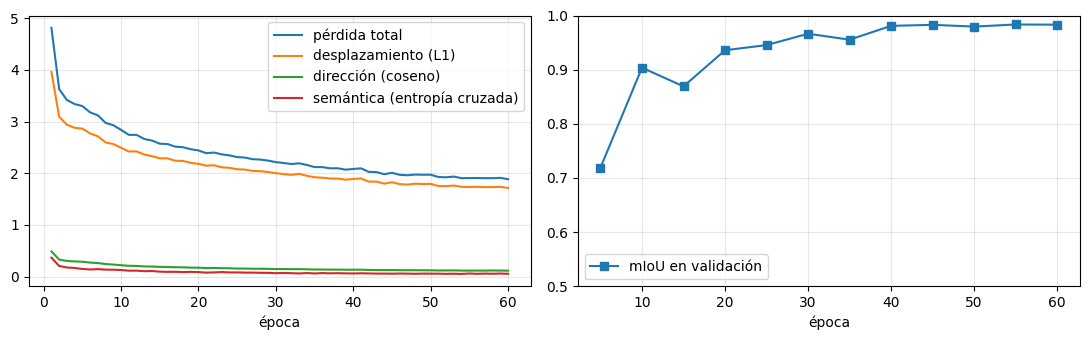

Tiempo de entrenamiento: 126.4 minutos


In [11]:
epocas = [h["epoca"] for h in historial]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(epocas, [h["perdida"] for h in historial], label="pérdida total")
ax[0].plot(epocas, [h["l1"] for h in historial], label="desplazamiento (L1)")
ax[0].plot(epocas, [h["dir"] for h in historial], label="dirección (coseno)")
ax[0].plot(epocas, [h["sem"] for h in historial], label="semántica (entropía cruzada)")
ax[0].set_xlabel("época")
ax[0].legend()
ax[0].grid(alpha=0.3)
val = [h for h in historial if "val_miou" in h]
ax[1].plot([h["epoca"] for h in val], [h["val_miou"] for h in val], "s-", label="mIoU en validación")
ax[1].set_xlabel("época")
ax[1].set_ylim(0.5, 1.0)
ax[1].legend()
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_RESULTADOS, "curvas_entrenamiento.png"), dpi=200)
plt.show()
print("Tiempo de entrenamiento:", historial[-1]["minutos"], "minutos")

## 8. Ajuste del agrupamiento con el conjunto de validación

El agrupamiento tiene tres valores que hay que escoger, que son el suavizado sigma, la distancia mínima entre centros y el número mínimo de puntos de un árbol. Se prueban varias combinaciones y se escoge la que da el mayor F1 en el conjunto de validación, sin usar nunca el conjunto de prueba.

En el experimento preliminar se vio que si el número mínimo de puntos se escoge solo con la vía de validación, puede salir muy grande y eliminar los árboles pequeños de otras vías. Por eso, como se explica en el documento, el número mínimo de puntos no puede ser mayor que el percentil 10 del tamaño de los árboles de entrenamiento. En esta celda también se compara con DBSCAN.

In [12]:
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
pred_val = [predecir_escena(modelo, e) for e in escenas_validacion]

tamanos = []
for e in escenas_entrenamiento:
    inst = np.asarray(e.instancia)
    tamanos.append(np.unique(inst[inst > 0], return_counts=True)[1])
limite_min_puntos = int(np.percentile(np.concatenate(tamanos), 10))
print("Percentil 10 del tamaño de los árboles de entrenamiento:", limite_min_puntos, "puntos")

opciones_min = sorted({m for m in [50, 100, 200, 300, 500, 1000] if m <= limite_min_puntos} | {limite_min_puntos})
mejor = None
for sigma in [0.3, 0.4, 0.6, 0.8, 1.0]:
    for dist_min in [1.5, 2.0, 3.0, 4.0]:
        for min_puntos in opciones_min:
            parametros = {"sigma": sigma, "dist_min": dist_min, "min_puntos": min_puntos}
            r = evaluar(escenas_validacion, pred_val, parametros)
            if mejor is None or r["f1"] > mejor[1]["f1"]:
                mejor = (parametros, r)
PARAMETROS = mejor[0]
print("Mejores parámetros en validación:", PARAMETROS, f"F1 = {100 * mejor[1]['f1']:.1f} %")

# comparación con DBSCAN en el mismo conjunto de validación
conteo = {"tp": 0, "fp": 0, "fn": 0, "suma_iou": 0.0}
for e, p in zip(escenas_validacion, pred_val):
    inst = agrupar_dbscan(np.asarray(e.xyz, np.float32), p["desp"], p["es_arbol"])
    for k, v in emparejar(inst, np.asarray(e.instancia)).items():
        conteo[k] += v
print(f"F1 en validación con DBSCAN: {100 * metricas_de_arboles(conteo)['f1']:.1f} %")
with open(os.path.join(CARPETA_RESULTADOS, "agrupamiento.json"), "w") as f:
    json.dump({"parametros": PARAMETROS, "f1_validacion": mejor[1]["f1"],
               "limite_min_puntos": limite_min_puntos}, f, indent=2)

Percentil 10 del tamaño de los árboles de entrenamiento: 597 puntos
Mejores parámetros en validación: {'sigma': 0.4, 'dist_min': 4.0, 'min_puntos': 200} F1 = 79.8 %
F1 en validación con DBSCAN: 27.5 %


## 9. Evaluación en el conjunto de prueba

El modelo final se evalúa en las calles de prueba con los parámetros escogidos en validación. Como la red escoge puntos al azar dentro de cada bloque, el resultado cambia un poco cada vez, entonces la evaluación se repite con tres semillas y se reportan el promedio y la desviación estándar. También se calcula el resultado sin aplicar los desplazamientos, para ver cuánto ayuda la cabeza de desplazamiento.

In [13]:
metricas = ["miou", "det", "omi", "com", "f1", "pq"]
resultados = {}
predicciones_guardadas = {}
for nombre, ciudad in PRUEBAS.items():
    escenas_prueba = cargar_escenas(ciudad, "prueba")
    por_semilla, sin_desp = [], []
    for semilla in [0, 1, 2]:
        random.seed(semilla)
        np.random.seed(semilla)
        torch.manual_seed(semilla)
        pred = [predecir_escena(modelo, e) for e in escenas_prueba]
        por_semilla.append(evaluar(escenas_prueba, pred, PARAMETROS))
        sin_desp.append(evaluar(escenas_prueba, pred, PARAMETROS, sin_desplazamiento=True))
        if semilla == 0:
            predicciones_guardadas[nombre] = (escenas_prueba, pred)
        print(f"{nombre} semilla {semilla}: F1 {100 * por_semilla[-1]['f1']:.1f} %")
    resultados[nombre] = {
        "ciudad": ciudad,
        "recorridos": len(escenas_prueba),
        "promedio": {k: float(np.mean([r[k] for r in por_semilla])) for k in metricas},
        "desviacion": {k: float(np.std([r[k] for r in por_semilla], ddof=1)) for k in metricas},
        "sin_desplazamientos": {k: float(np.mean([r[k] for r in sin_desp])) for k in metricas},
        "arboles_reales": por_semilla[0]["arboles_reales"],
        "arboles_predichos": float(np.mean([r["arboles_predichos"] for r in por_semilla])),
    }

with open(os.path.join(CARPETA_RESULTADOS, "resultados.json"), "w") as f:
    json.dump(resultados, f, indent=2)

print()
print(f"{'Experimento':<28}" + "".join(f"{m:>14}" for m in ["mIoU", "Det", "Omi", "Com", "F1", "PQ"]))
for nombre, r in resultados.items():
    print(f"{nombre + ' (' + r['ciudad'] + ')':<28}" +
          "".join(f"{100 * r['promedio'][m]:>8.1f} ± {100 * r['desviacion'][m]:<3.1f}" for m in metricas))
    print(f"{'   sin desplazamientos':<28}" + "".join(f"{100 * r['sin_desplazamientos'][m]:>14.1f}" for m in metricas))
    print(f"   árboles reales {r['arboles_reales']}, predichos en promedio {r['arboles_predichos']:.0f}")

E3 semilla 0: F1 51.0 %
E3 semilla 1: F1 50.1 %
E3 semilla 2: F1 50.6 %

Experimento                           mIoU           Det           Omi           Com            F1            PQ
E3 (whu-stree-nj)               73.7 ± 0.1    52.4 ± 0.3    47.6 ± 0.3    51.1 ± 0.5    50.6 ± 0.4    40.7 ± 0.3
   sin desplazamientos                73.7          42.5          57.5          64.7          38.5          29.6
   árboles reales 3586, predichos en promedio 3846


## 10. Resultados cualitativos

Para ver cómo se comporta el modelo, se toma una zona de 70 por 40 m de una calle de prueba, la que tiene más árboles, y se compara la referencia con la predicción. Cada color es un árbol y los puntos grises no son árbol. Arriba se ve la zona desde arriba y abajo la vista lateral de uno de los lados de la calle.

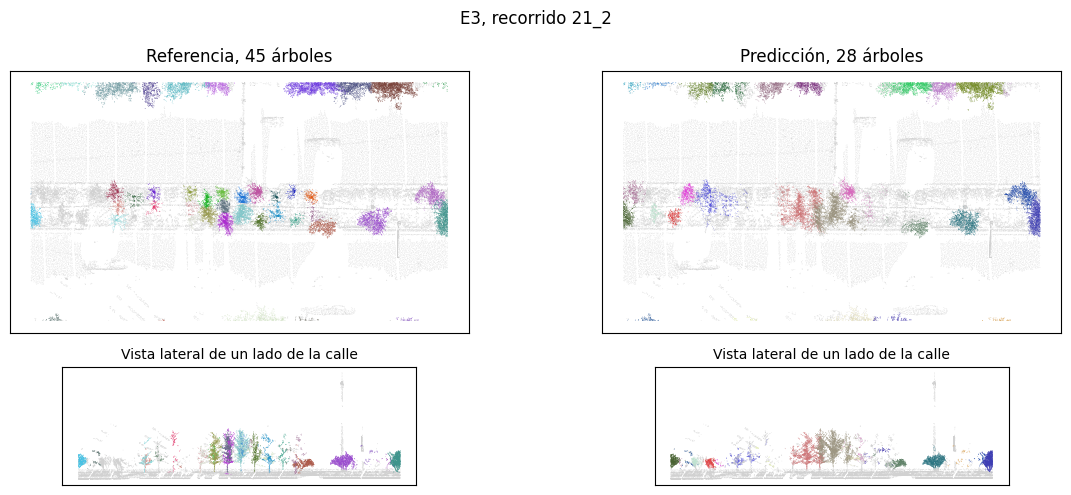

In [14]:
def colores(ids, semilla):
    rng = np.random.default_rng(semilla)
    paleta = rng.uniform(0.1, 0.9, size=(int(ids.max()) + 1, 3))
    c = paleta[ids]
    c[ids <= 0] = (0.82, 0.82, 0.82)
    return c


for nombre, (escenas_prueba, pred) in predicciones_guardadas.items():
    j = int(np.argmax([len(np.unique(np.asarray(e.instancia))) for e in escenas_prueba]))
    escena = escenas_prueba[j]
    xyz = np.asarray(escena.xyz)
    real = np.asarray(escena.instancia)
    prediccion = agrupar_picos(xyz, pred[j]["desp"], pred[j]["es_arbol"], **PARAMETROS)

    # se gira la calle para que quede horizontal en la figura
    xy = xyz[:, :2] - xyz[:, :2].mean(0)
    muestra = np.random.default_rng(0).choice(len(xy), min(20000, len(xy)), replace=False)
    _, _, vt = np.linalg.svd(xy[muestra], full_matrices=False)
    xy = xy @ vt.T

    # se busca la ventana de 70 x 40 m con más árboles
    arboles = np.flatnonzero(real > 0)
    mejor_centro, mas_arboles = xy.mean(0), -1
    for c in xy[np.random.default_rng(0).choice(arboles, min(400, len(arboles)), replace=False)]:
        m = (np.abs(xy[:, 0] - c[0]) < 35) & (np.abs(xy[:, 1] - c[1]) < 20)
        n = len(np.unique(real[m & (real > 0)]))
        if n > mas_arboles:
            mejor_centro, mas_arboles = c, n
    m = (np.abs(xy[:, 0] - mejor_centro[0]) < 35) & (np.abs(xy[:, 1] - mejor_centro[1]) < 20)
    p, z, r, q = xy[m], xyz[m, 2], real[m], prediccion[m]
    orden = np.argsort(z)
    lado = p[:, 1] < mejor_centro[1]

    fig, ax = plt.subplots(2, 2, figsize=(12, 5), gridspec_kw={"height_ratios": [40, 18]})
    for k, (titulo, col) in enumerate([(f"Referencia, {len(np.unique(r[r > 0]))} árboles", colores(r, 3)),
                                       (f"Predicción, {len(np.unique(q[q > 0]))} árboles", colores(q, 11))]):
        ax[0, k].scatter(p[orden, 0], p[orden, 1], c=col[orden], s=0.15, linewidths=0)
        ax[0, k].set_title(titulo)
        ax[1, k].scatter(p[lado, 0], z[lado], c=col[lado], s=0.15, linewidths=0)
        ax[1, k].set_title("Vista lateral de un lado de la calle", fontsize=10)
        for a in ax[:, k]:
            a.set_aspect("equal")
            a.set_xticks([])
            a.set_yticks([])
    fig.suptitle(f"{nombre}, recorrido {escena.nombre}")
    plt.tight_layout()
    plt.savefig(os.path.join(CARPETA_RESULTADOS, f"cualitativo_{nombre}.png"), dpi=200)
    plt.show()

## 11. Guardar los resultados

Esta celda junta en un archivo .zip los resultados, la tabla, las curvas de entrenamiento y las figuras, para pasarlos al documento. El archivo queda en la carpeta arbolado_resultados de Google Drive.

In [15]:
archivo_zip = shutil.make_archive(os.path.join(os.path.dirname(CARPETA_RESULTADOS), "resultados_" + EXPERIMENTO),
                                  "zip", CARPETA_RESULTADOS)
print("Resultados guardados en", archivo_zip)

Resultados guardados en /content/drive/MyDrive/arbolado_resultados/resultados_E3.zip


Los resultados de este notebook se analizan en la sección de resultados del documento del proyecto, donde se comparan con los resultados publicados por los autores de WHU-STree.